# Exploratory Data Analysis: Finding Outliers

Part of my IBM Data Analyst Capstone project. In this notebook I look at the developer survey for extreme values, focusing on yearly compensation. I flag outliers with two methods (3 standard deviations from the mean and the interquartile range), remove them, and then look at correlations with age.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [2]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

df = pd.read_csv(file_url)
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


## 2. Respondents by industry

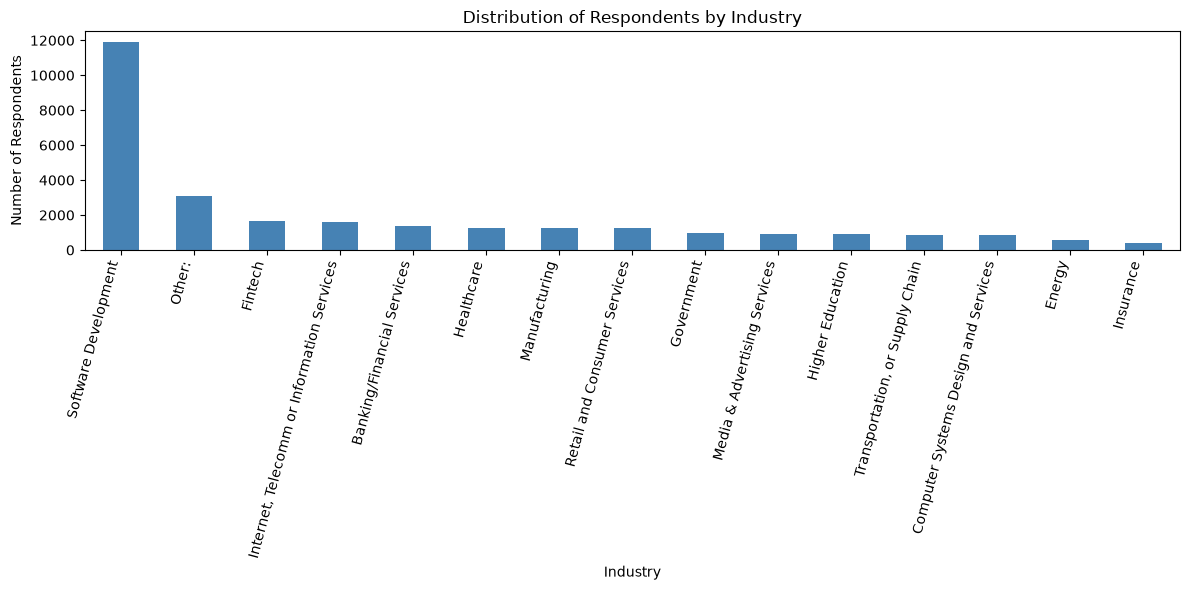

Industry
Software Development                          11918
Other:                                         3077
Fintech                                        1641
Internet, Telecomm or Information Services     1629
Banking/Financial Services                     1371
Healthcare                                     1277
Manufacturing                                  1265
Retail and Consumer Services                   1264
Government                                      962
Media & Advertising Services                    894
Higher Education                                890
Transportation, or Supply Chain                 859
Computer Systems Design and Services            844
Energy                                          578
Insurance                                       389
Name: count, dtype: int64

In [3]:
industry_counts = df['Industry'].value_counts()

plt.figure(figsize=(12, 6))
industry_counts.plot(kind='bar', color='steelblue')
plt.title('Distribution of Respondents by Industry')
plt.xlabel('Industry')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

print(industry_counts)

## 3. High compensation outliers: 3 standard deviations
Flag respondents whose yearly compensation is more than 3 standard deviations above the mean.

In [4]:
col = 'ConvertedCompYearly'

mean_comp = df[col].mean()
median_comp = df[col].median()
std_comp = df[col].std()
print(f"Mean: {mean_comp:,.2f}")
print(f"Median: {median_comp:,.2f}")
print(f"Std Dev: {std_comp:,.2f}")

# Threshold: 3 standard deviations above the mean
threshold = mean_comp + 3 * std_comp
high_comp = df[df[col] > threshold]
print(f"Threshold: {threshold:,.2f}")
print(f"Respondents above threshold: {len(high_comp)}")
high_comp[[col]].describe()

Mean: 86,155.29
Median: 65,000.00
Std Dev: 186,756.97
Threshold: 646,426.21
Respondents above threshold: 89

,ConvertedCompYearly
count,8.900000e+01
mean,1.623895e+06
std,2.366560e+06
min,6.500000e+05
25%,7.500000e+05
50%,1.000000e+06
75%,1.332930e+06
max,1.625660e+07


The mean (about 86,155) is well above the median (65,000), which shows that a few very high values pull the average up. 89 respondents are above the 646,426 threshold, and the highest value is about 16.3 million.

## 4. Outliers with the interquartile range (IQR)
Values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR are treated as outliers.

Q1: 32,712.00, Q3: 107,971.50, IQR: 75,259.50
Lower bound: -80,177.25, Upper bound: 220,860.75
Number of outliers: 978

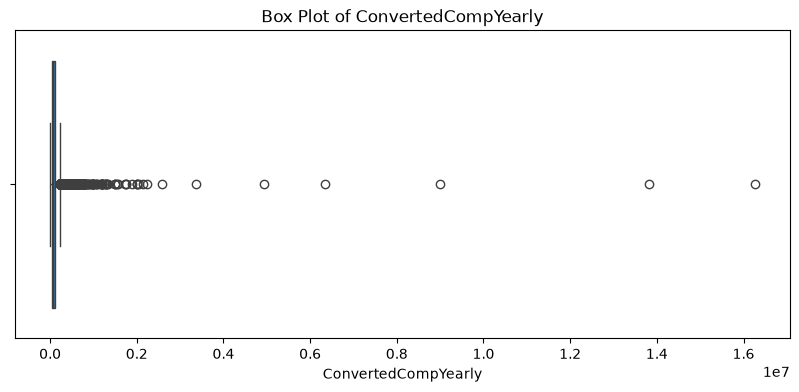

In [5]:
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Q1: {Q1:,.2f}, Q3: {Q3:,.2f}, IQR: {IQR:,.2f}")
print(f"Lower bound: {lower_bound:,.2f}, Upper bound: {upper_bound:,.2f}")

outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
print(f"Number of outliers: {len(outliers)}")

plt.figure(figsize=(10, 4))
sns.boxplot(x=df[col])
plt.title('Box Plot of ConvertedCompYearly')
plt.show()

## 5. Remove outliers
A comparison with `NaN` is always false, so filtering on the compensation bounds directly would also drop everyone who did not report pay. In the lab's original code this showed up as 42,980 rows removed, which is 978 outliers plus 42,002 respondents with no compensation. Here I keep the two groups apart: first select respondents who reported pay, then remove the outliers among them.

In [ ]:
# Respondents with no reported compensation are not outliers, so they are counted separately
reported = df[df[col].notna()]
df_no_outliers = reported[(reported[col] >= lower_bound) & (reported[col] <= upper_bound)].copy()

print("Rows in the full dataset:", len(df))
print("Rows with reported compensation:", len(reported))
print("Outliers removed:", len(reported) - len(df_no_outliers))
print("Rows in the new DataFrame:", len(df_no_outliers))

## 6. Correlation with age
Map the age ranges to approximate midpoints and correlate age with the other numeric columns.

In [ ]:
age_map = {
    'Under 18 years old': 16,
    '18-24 years old': 21,
    '25-34 years old': 29.5,
    '35-44 years old': 39.5,
    '45-54 years old': 49.5,
    '55-64 years old': 59.5,
    '65 years or older': 70,
}
df_no_outliers['Age_numeric'] = df_no_outliers['Age'].map(age_map)

# ResponseId is just an identifier and CompTotal mixes currencies, so neither is meaningful to correlate
numeric_df = df_no_outliers.select_dtypes(include='number').drop(columns=['ResponseId', 'CompTotal'])
corr_matrix = numeric_df.corr()
print(corr_matrix['Age_numeric'].sort_values(ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

Age is strongly related to work experience (about 0.84, as expected), moderately related to compensation (about 0.37), and barely related to job satisfaction (about 0.07).